This notebook asks key questions related to the matches and player appearances in the 2025-2026 football season running from 10th July 2025 to 31st May 2026. This notebook either requires that you either run the cleaning notebook to get the csv or have csv downloaded (made available in git hub) to import it here.

In [104]:
import pandas as pd

In [39]:
df = pd.read_csv(
    "analysis_dataset.csv",
    dtype={"player_aiff_id_
    cleaned": "string"}
)

In [40]:
df.shape
# our dataset has 225,993 rows and 25 columns. This is the dataset for youth boys club leagues between a specified date range.

(225993, 25)

In [41]:
df.columns

Index(['match_id', 'competition_id', 'competition_name', 'match_date',
       'match_venue', 'match_stadium', 'ft', 'ft_text', 'team_type',
       'player_name', 'player_id', 'player_aiff_id', 'player_team_id',
       'status', 'one_team_player_data_missing', 'substituted', 'team_name',
       'AI_level', 'AI_state', 'AI_age', 'AI_primary_format_teams',
       'AI_gender', 'player_name_clean', 'player_aiff_id_cleaned',
       'appearance'],
      dtype='str')

The dataset contains one row per **player–match appearance**.

Relevant variables include:

* `match_id`: Unique identifier for the match.
* `competition_id`: Identifier for the competition the match belongs to.
* `competition_name`: Name of the competition.
* `match_date`: Date on which the match was played.
* `venue` and `stadium`: Match location.
* `player_name` and `player_aiff_id_cleaned`: Player identifiers. (`player_id` is not used.)
* `player_team_name` and `player_team_id`: The team the player represented in that match.
* `one_team_missing`: Indicates whether the player comes from one of the 699 matches where player data for the opposing team is missing.
* `substituted_on`: Indicates whether the player entered the match as a substitute.

The following variables are not used in the analysis:

* `ft`, `ft_text`, and `team_type`.
* `AI_gender`, `AI_age`, and `AI_level`, as the analysis is restricted to male youth club-league competitions.


In [105]:
# What is the date range?
df["match_date"] = pd.to_datetime(df["match_date"])

print(
    f"The dataset covers matches played between "
    f"{df['match_date'].min():%d %B %Y} and {df['match_date'].max():%d %B %Y}."
)

The dataset covers matches played between 12 July 2025 and 31 May 2026.


In [43]:
df['player_aiff_id_cleaned'].value_counts()

player_aiff_id_cleaned
231366    70
231397    70
177170    70
253659    65
162922    61
          ..
522818     1
517744     1
519501     1
517713     1
519241     1
Name: count, Length: 22855, dtype: Int64

### Competition landscape

In [44]:
# How many competitions happened in this season across the nation? 
df.groupby("AI_level")["competition_id"].nunique()

AI_level
District     9
National     4
State       38
Name: competition_id, dtype: int64

A total of **51 youth club leagues** were identified during the study period.

- **State-level leagues dominated the landscape**, accounting for **38 of the 51 leagues (74.5%)**.
- **District-level leagues** accounted for **9 competitions (17.6%)**.
- **National-level leagues** accounted for the remaining **4 competitions (7.8%)**.

Of the four national youth club leagues, **three (75%)** were organized directly by the **All India Football Federation (AIFF)**: the AIFF Elite Youth League, AIFF Junior League and AIFF Sub Junior League. The fourth was the **Reliance Foundation Development League**, organized by the Reliance Foundation.

#### Classification used in this analysis

- **National:** Competitions that bring together clubs through a structure operating across multiple states or regions and culminating at the national level.
- **State:** Competitions organized at or limited primarily to a single state.
- **District:** Competitions organized at or limited primarily to a district, city or district football association.

In [45]:
df['AI_state'].value_counts()

AI_state
National            93179
Goa                 27076
Maharashtra         24854
Karnataka           17148
Gujarat             16875
West Bengal         12383
Kerala               8927
Rajasthan            7056
Delhi                6021
Himachal Pradesh     4928
Madhya Pradesh       2397
Puducherry           1815
Punjab               1694
Assam                1287
Odisha                353
Name: count, dtype: int64

In [46]:
# What competitions happened in this season across the nation?
df.groupby("AI_level")["competition_name"].value_counts()
# either their states organise youth leagues or they send their players to national leagues

AI_level  competition_name                                                            
District  Poona District Football Association - Under 15 Youth League - 2025-26            5768
          Poona District Football Association - Under 13 Youth League - 2025-26            5111
          Delhi Future Stars Youth League U-15 2025/26                                     2678
          Poona District Football Association - Under 17 Youth League - 2025-26            2658
          Delhi Future Stars Youth League U-13 2025/26                                     1989
          Thane Sub - Junior (U-13) 2013-2014 Youth League Boys 2025-2026                   648
          Kensington Football Tournament U-13                                               141
          Thane Junior (U-15) 2011-2012 Youth League 2025-2026                               60
          Thane Elite Youth League 2009-2010 (U-17) 2025 - 2026                              48
National  AIFF Elite Youth League 2025-26        

In [10]:
# which states conducted the most state youth leagues? (each league's duration could be different, don't interpret it as more competitions!)
state_competitions = (
    df.loc[df["AI_level"] == "State", ["competition_id", "AI_state"]]
      .drop_duplicates()
)

state_summary = (
    state_competitions["AI_state"]
    .value_counts()
    .rename_axis("state")
    .reset_index(name="competitions")
)

state_summary["pct_of_state_competitions"] = (
    state_summary["competitions"]
    / state_summary["competitions"].sum()
    * 100
).round(1)

state_summary

#this sums to 38 competitions, FYI. 

,state,competitions,pct_of_state_competitions
0,Goa,7,18.4
1,Karnataka,5,13.2
2,Maharashtra,4,10.5
3,Gujarat,3,7.9
4,West Bengal,3,7.9
5,Kerala,3,7.9
6,Himachal Pradesh,3,7.9
7,Puducherry,2,5.3
8,Rajasthan,2,5.3
9,Assam,2,5.3


**6 states account for 66% of all state youth leagues**: Goa, Karnataka, Maharashtra, Gujarat, West Bengal and Kerala together accounted for 25 of the 38 state-level youth club leagues in the dataset, or 65.8%. Goa alone accounted for the largest share, with seven competitions, followed by Karnataka with five and Maharashtra with four.

The remaining 13 competitions were spread across Himachal Pradesh, Puducherry, Rajasthan, Assam, Punjab, Odisha, Madhya Pradesh and Delhi.

In [11]:
# which districts conducted the most district youth leagues? (each league's duration could be different, don't interpret it as more competitions!)
district_competitions = (
    df.loc[df["AI_level"] == "District", ["competition_id", "AI_state"]]
      .drop_duplicates()
)

district_summary = (
    district_competitions["AI_state"]
    .value_counts()
    .rename_axis("state")
    .reset_index(name="competitions")
)

district_summary["pct_of_district_competitions"] = (
    district_summary["competitions"]
    / district_summary["competitions"].sum()
    * 100
).round(1)

district_summary

#this sums to 9 competitions, FYI. 

,state,competitions,pct_of_district_competitions
0,Maharashtra,7,77.8
1,Delhi,2,22.2


* District-level youth club leagues were identified in only two states.
* Maharashtra accounted for seven of the nine district competitions in the dataset, or 77.8%, while Delhi accounted for the remaining two.
* This suggests that district-level league coverage in the dataset was highly geographically concentrated. However, the result should not be interpreted as evidence that other states had no district youth football: such competitions may not have been recorded in the AIFF match-centre data, may have been classified differently, or may not have taken place during the study period.

In [12]:
df["AI_level_modified"] = df["AI_level"].replace({
    "State": "State + District",
    "District": "State + District"
})

In [13]:
# Which states conducted the most state- or district-level youth leagues?
# Each league may have a different duration, so this counts competitions,
# not the volume of football played.

state_district_competitions = (
    df.loc[
        df["AI_level_modified"] == "State + District",
        ["competition_id", "AI_state"]
    ]
    .drop_duplicates()
)

state_district_summary = (
    state_district_competitions["AI_state"]
    .value_counts()
    .rename_axis("state")
    .reset_index(name="competitions")
)

state_district_summary["pct_of_state_district_competitions"] = (
    state_district_summary["competitions"]
    / state_district_summary["competitions"].sum()
    * 100
).round(1)

state_district_summary

,state,competitions,pct_of_state_district_competitions
0,Maharashtra,11,23.4
1,Goa,7,14.9
2,Karnataka,5,10.6
3,Gujarat,3,6.4
4,West Bengal,3,6.4
5,Delhi,3,6.4
6,Kerala,3,6.4
7,Himachal Pradesh,3,6.4
8,Puducherry,2,4.3
9,Rajasthan,2,4.3


### Teams landscape

In [14]:
df.columns

Index(['match_id', 'competition_id', 'competition_name', 'match_date',
       'match_venue', 'match_stadium', 'ft', 'ft_text', 'team_type',
       'player_name', 'player_id', 'player_aiff_id', 'player_team_id',
       'status', 'one_team_player_data_missing', 'substituted', 'team_name',
       'AI_level', 'AI_state', 'AI_age', 'AI_primary_format_teams',
       'AI_gender', 'player_name_clean', 'player_aiff_id_cleaned',
       'appearance', 'AI_level_modified'],
      dtype='str')

In [15]:
df['team_name'].value_counts()

team_name
SESA Football Academy            3216
Dempo Sports Club                3150
FC Goa                           2999
Alchemy International FA         2935
Kerala Blasters Football Club    2842
                                 ... 
CFC Kings                          15
THANE - Seawoods FC                15
 RISING CHAMPS                     14
BHUBANESWAR DAA                    13
RISING STAR CLUB                   10
Name: count, Length: 547, dtype: int64

In [16]:
df.groupby("team_name")["player_aiff_id_cleaned"].nunique().describe()

count    547.000000
mean      43.277879
std       34.505395
min        9.000000
25%       19.000000
50%       28.000000
75%       58.500000
max      203.000000
Name: player_aiff_id_cleaned, dtype: float64

### Match landscape

In [17]:
# How many matches happened in this season across the nation? / How many matches did these competitions generate?
df.groupby("AI_level")["match_id"].nunique()

AI_level
District     497
National    1755
State       2684
Name: match_id, dtype: int64

The **51 youth club leagues** generated a total of **4,936 matches** during the 2025–26 season, averaging **97 matches per league.**


- **State-level leagues** generated **2,684 matches (54.4%)**.
- **National-level leagues** generated **1,755 matches (35.6%)**.
- **District-level leagues** generated **497 matches (10.1%)**.

Although national leagues accounted for only **4 of the 51 competitions (7.8%)**, they generated more than a **third of all matches (35.6%)**. By contrast, state leagues accounted for **74.5% of all competitions** but **54.4% of matches**.

| Level | Competitions | Matches | Average matches per competition |
|:------|-------------:|--------:|--------------------------------:|
| National | 4 | 1,755 | 438.8 |
| State | 38 | 2,684 | 70.6 |
| District | 9 | 497 | 55.2 |

On average, a national youth league generated **439 matches**—more than **six times** the average state league (**71 matches**) and almost **eight times** the average district league (**55 matches**).

This highlights an important feature of the youth football ecosystem: while national leagues are few in number, they generate a disproportionately large share of competitive match opportunities. The next question is whether these opportunities translate into enough match appearances for individual players.

In [18]:
# does AIFF dominate the national match landscape?
national_matches = (
    df[df["AI_level"] == "National"]
    .groupby("competition_name")
    .agg(matches=("match_id", "nunique"))
    .sort_values("matches", ascending=False)
    .reset_index()
)

national_matches["pct_of_national_matches"] = (
    national_matches["matches"]
    / national_matches["matches"].sum()
    * 100
).round(1)

national_matches

,competition_name,matches,pct_of_national_matches
0,AIFF Elite Youth League 2025-26,582,33.2
1,AIFF Sub Junior League 2025-26,491,28.0
2,AIFF Junior League 2025-26,421,24.0
3,Reliance Foundation Development League 2025-26,261,14.9


The national youth league calendar was dominated by the three AIFF-run leagues. Together, the **AIFF Elite Youth League**, **AIFF Sub Junior League** and **AIFF Junior League** generated **1,494 of the 1,755 national league matches (85.1%)** during the 2025–26 season.

The **Reliance Foundation Development League** accounted for the remaining **261 matches (14.9%)**.

Although the AIFF organized **three of the four national youth club leagues (75%)**, those competitions generated **85.1% of all national league matches**, highlighting the central role of the AIFF's league structure in creating national-level match opportunities.

In [19]:
# which states produce the most number of matches in state leagues? 
state_matches = (
    df.loc[df["AI_level"] == "State"]
    .groupby("AI_state")
    .agg(
        competitions=("competition_id", "nunique"),
        matches=("match_id", "nunique")
    )
    .sort_values("matches", ascending=False)
    .reset_index()
)

state_matches["pct_of_state_matches"] = (
    state_matches["matches"]
    / state_matches["matches"].sum()
    * 100
).round(1)

state_matches["avg_matches_per_competition"] = (
    state_matches["matches"]
    / state_matches["competitions"]
).round(1)

state_matches

,AI_state,competitions,matches,pct_of_state_matches,avg_matches_per_competition
0,Goa,7,613,22.8,87.6
1,Karnataka,5,488,18.2,97.6
2,Gujarat,3,372,13.9,124.0
3,West Bengal,3,292,10.9,97.3
4,Maharashtra,4,235,8.8,58.8
5,Himachal Pradesh,3,168,6.3,56.0
6,Kerala,3,167,6.2,55.7
7,Rajasthan,2,115,4.3,57.5
8,Madhya Pradesh,1,59,2.2,59.0
9,Puducherry,2,53,2.0,26.5


State-level youth leagues generated **2,684 matches** during the 2025–26 season from 38 youth leagues.

Goa’s seven leagues generated the largest number of matches: **613, or 22.8% of all state-level matches**. Karnataka followed with **488 matches (18.2%)**, while Gujarat generated **372 matches (13.9%)**.

Together, Goa, Karnataka and Gujarat accounted for **1,473 of the 2,684 state-level matches (54.9%)**. 

**Goa had the highest total match volume, while Gujarat’s individual leagues were the largest on average.**

In [20]:
# which district produce the most number of matches in district leagues? 
district_matches = (
    df.loc[df["AI_level"] == "District"]
    .groupby("AI_state")
    .agg(
        competitions=("competition_id", "nunique"),
        matches=("match_id", "nunique")
    )
    .sort_values("matches", ascending=False)
    .reset_index()
)

district_matches["pct_of_state_matches"] = (
    district_matches["matches"]
    / district_matches["matches"].sum()
    * 100
).round(1)

district_matches["avg_matches_per_competition"] = (
    district_matches["matches"]
    / district_matches["competitions"]
).round(1)

district_matches

,AI_state,competitions,matches,pct_of_state_matches,avg_matches_per_competition
0,Maharashtra,7,364,73.2,52.0
1,Delhi,2,133,26.8,66.5


District-level youth leagues generated **497 matches** during the 2025–26 season across **9 leagues**

Maharashtra accounted for **364 matches (73.2%)**, while Delhi accounted for the remaining **133 matches (26.8%)**.

| State | Competitions | Matches | Share of district-level matches | Average matches per competition |
|:--|--:|--:|--:|--:|
| Maharashtra | 7 | 364 | 73.2% | 52.0 |
| Delhi | 2 | 133 | 26.8% | 66.5 |

Maharashtra generated the larger total number of district-level matches because it had more observed competitions. Delhi’s two district leagues, however, were larger on average, generating **66.5 matches per competition**, compared with **52 matches per competition** in Maharashtra.

Because district-level leagues were identified in only two states, these figures should be treated as a description of the leagues captured in the dataset rather than a complete comparison of district football systems across India.

### Player appearance landscape

In [48]:
df["appearance"] = (
    (df["status"] == 1)
    | (
        (df["status"] == 2)
        & (df["substituted"] == True)
    )
)

In [76]:
# creating dataset of players who did appear 
appearances = df.loc[df["appearance"]].copy()

In [77]:
player_appearances = (
    appearances
    .groupby("player_aiff_id_cleaned")
    .agg(
        player_name=("player_name", "first"),
        matches_played=("match_id", "nunique"),
        competitions_played=("competition_id", "nunique")
    )
    .reset_index()
)

In [78]:
player_appearances

,player_aiff_id_cleaned,player_name,matches_played,competitions_played
0,100035,Yendrembam Boby Singh,21,1
1,100096,Mocha Irom,19,1
2,100847,Pratap Biswas,1,1
3,102091,Konsam Akash Singh,21,1
4,102298,Alvin Shibi Thomas (loc),13,1
...,...,...,...,...
19713,99712,Shine Arogiam,4,1
19714,99762,Khaleel Rahman,5,1
19715,99778,Alan Wilson,4,1
19716,99832,Saviyol Varghese,7,1


In [51]:
df['player_aiff_id_cleaned'].value_counts()

player_aiff_id_cleaned
231366    70
231397    70
177170    70
253659    65
162922    61
          ..
522818     1
517744     1
519501     1
517713     1
519241     1
Name: count, Length: 22855, dtype: Int64

In [26]:
player_appearances['player_aiff_id_cleaned'].value_counts()

player_aiff_id_cleaned
100035    1
100096    1
100847    1
102091    1
102298    1
         ..
99712     1
99762     1
99778     1
99832     1
99833     1
Name: count, Length: 19718, dtype: Int64

In [52]:
player_appearances["matches_played"].describe()

count    19718.000000
mean         6.548889
std          5.492854
min          1.000000
25%          2.000000
50%          5.000000
75%          9.000000
max         48.000000
Name: matches_played, dtype: float64

A player was considered to have made an appearance if they either:
- started the match (`status = 1`), or
- came on as a substitute (`status = 2` and `substituted_on = True`).

Players who remained on the bench or were not brought on were not counted as having made an appearance.

Among the **22,855 unique players** in the dataset, **19,718 (86.3%)** recorded at least one match appearance during the 2025–26 season.  Note that appearance does not mean every player spent the same time on the field. This analysis does not talk about playing minutes.

The **median player** made **5 appearances**, while the **average player** made **6.5 appearances**. One in four players made **2 appearances or fewer**, half made **5 or fewer**, and three-quarters made **9 or fewer**. Even at the 90th percentile, players had made only **14 appearances**, while those at the 95th percentile had made **17 appearances**.

The highest recorded total was **48 appearances**.

The AIFF's *Vision 2047* identifies **35 competitive matches per player per season** as a development target. By comparison, the median player in this dataset recorded only **5 appearances**—around **one-seventh of that benchmark**.

In [54]:
player_appearances["matches_played"].quantile(
    [0.25, 0.5, 0.75, 0.9, 0.95]
)

0.25     2.0
0.50     5.0
0.75     9.0
0.90    14.0
0.95    17.0
Name: matches_played, dtype: float64

* One in four players made 2 appearances or fewer during the season.
* Half of all players made 5 appearances or fewer.
* Three in four players made 9 appearances or fewer.
* Even among the top 10% of players, most made 14 appearances or fewer.
* Even among the top 5% of players, most made 17 appearances or fewer.

In [55]:
(player_appearances["matches_played"] >= 10).mean() * 100

np.float64(22.852216249112487)

In [56]:
# Where did the average player's appearances come from?

# One row per player per competition level
player_level_appearances = (
    appearances
    .drop_duplicates(
        subset=["player_aiff_id_cleaned", "match_id"]
    )
    .groupby(["player_aiff_id_cleaned", "AI_level"])
    .agg(appearances=("match_id", "nunique"))
    .reset_index()
)

# Put National, State and District appearances into separate columns
player_level_wide = (
    player_level_appearances
    .pivot(
        index="player_aiff_id_cleaned",
        columns="AI_level",
        values="appearances"
    )
    .fillna(0)
    .reset_index()
)

player_level_wide.columns.name = None

# Ensure every expected level exists
for level in ["National", "State", "District"]:
    if level not in player_level_wide.columns:
        player_level_wide[level] = 0

average_appearances_by_level = (
    player_level_wide[
        ["National", "State", "District"]
    ]
    .mean()
    .round(2)
    .rename("average_appearances")
    .reset_index()
    .rename(columns={"index": "level"})
)

average_appearances_by_level

,level,average_appearances
0,National,2.59
1,State,3.39
2,District,0.57


In [57]:
average_appearances_by_level["average_appearances"].sum()

np.float64(6.550000000000001)

In [32]:
average_appearances_by_level["share_pct"] = (
    average_appearances_by_level["average_appearances"]
    / average_appearances_by_level["average_appearances"].sum()
    * 100
).round(1)

average_appearances_by_level

,level,average_appearances,share_pct
0,National,2.59,39.5
1,State,3.39,51.8
2,District,0.57,8.7


The average player with at least one appearance accumulated:
* 3.39 appearances (52%) in state leagues
* 2.59 appearances (40%) in national leagues
* 0.57 appearances (9%) in district leagues

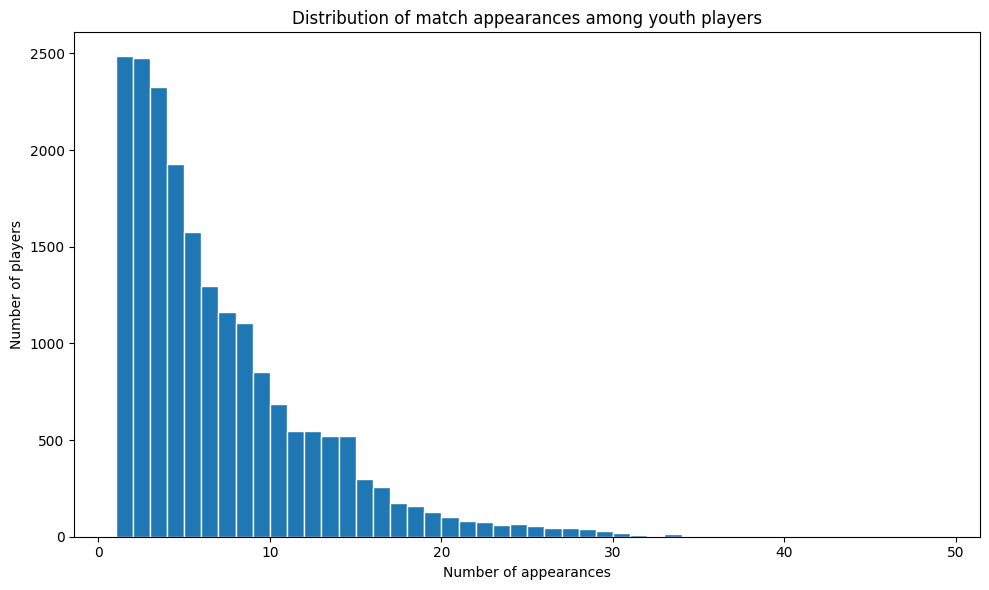

In [33]:
# bar graph to see distribution 
player_appearances = (
    df[df["appearance"]]
    .groupby("player_aiff_id_cleaned")
    .agg(
        player_name=("player_name", "first"),
        appearances=("match_id", "nunique")
    )
    .reset_index()
)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    player_appearances["appearances"],
    bins=range(
        1,
        int(player_appearances["appearances"].max()) + 2
    ),
    edgecolor="white"
)

ax.set_xlabel("Number of appearances")
ax.set_ylabel("Number of players")
ax.set_title("Distribution of match appearances among youth players")

plt.tight_layout()
plt.show()

In [34]:
hist_data = (
    player_appearances["appearances"]
    .value_counts()
    .sort_index()
    .rename_axis("appearances")
    .reset_index(name="players")
)

hist_data

,appearances,players
0,1,2485
1,2,2475
2,3,2327
3,4,1929
4,5,1577
5,6,1298
6,7,1161
7,8,1106
8,9,854
9,10,684


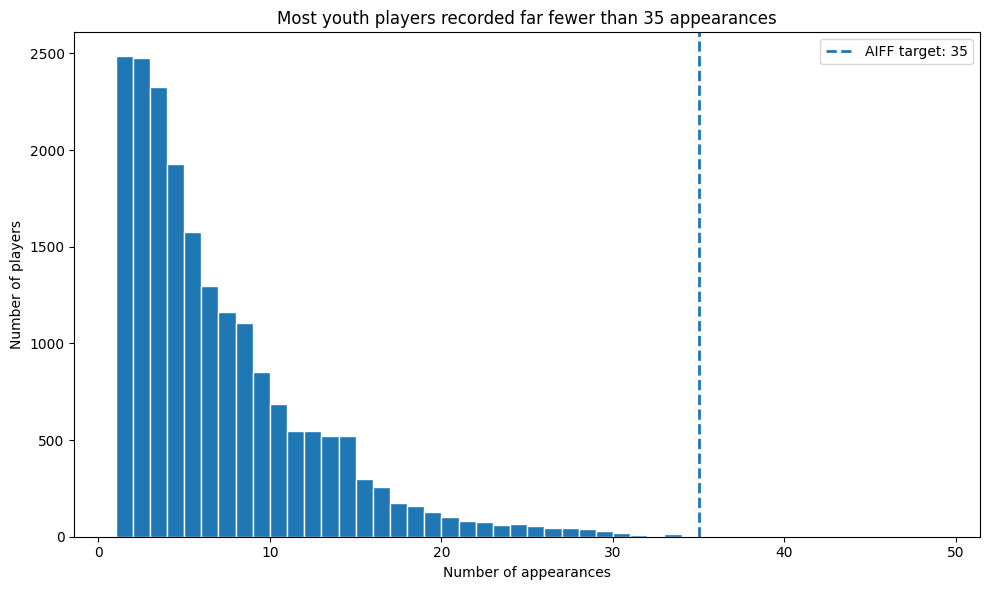

In [35]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    player_appearances["appearances"],
    bins=range(
        1,
        int(player_appearances["appearances"].max()) + 2
    ),
    edgecolor="white"
)

ax.axvline(
    35,
    linestyle="--",
    linewidth=2,
    label="AIFF target: 35"
)

ax.set_xlabel("Number of appearances")
ax.set_ylabel("Number of players")
ax.set_title("Most youth players recorded far fewer than 35 appearances")
ax.legend()

plt.tight_layout()
plt.show()

In [58]:
# do players with more appearances have to play more matches?
import numpy as np

player_appearances["appearance_band"] = pd.cut(
    player_appearances["matches_played"],
    bins=[0, 5, 10, 20, 30, np.inf],
    labels=["1–5", "6–10", "11–20", "21–30", "31+"],
    right=True
)

competitions_by_appearance_band = (
    player_appearances
    .groupby("appearance_band", observed=True)
    .agg(
        players=("player_aiff_id_cleaned", "count"),
        average_matches=("matches_played", "mean"),
        median_matches=("matches_played", "median"),
        average_competitions=("competitions_played", "mean"),
        median_competitions=("competitions_played", "median"),
        min_competitions=("competitions_played", "min"),
        max_competitions=("competitions_played", "max")
    )
    .reset_index()
)

competitions_by_appearance_band
# Most players accumulated their appearances within a single competition. 
# Players with 21–30 appearances typically played in two competitions, while those with 31 or more typically played in three.

,appearance_band,players,average_matches,median_matches,average_competitions,median_competitions,min_competitions,max_competitions
0,1–5,10793,2.781154,3.0,1.021032,1.0,1,3
1,6–10,5103,7.699197,8.0,1.112483,1.0,1,3
2,11–20,3256,13.990172,14.0,1.361179,1.0,1,3
3,21–30,524,24.517176,24.0,2.143130,2.0,1,4
4,31+,42,33.952381,33.0,2.738095,3.0,2,4


In [62]:
players_over_10 = player_appearances.loc[
    player_appearances["matches_played"] > 10
]

n_over_10 = players_over_10["player_aiff_id_cleaned"].nunique()
n_total = player_appearances["player_aiff_id_cleaned"].nunique()

share_over_10 = n_over_10 / n_total * 100

print(f"Players with more than 10 appearances: {n_over_10:,}")
print(f"Share of players: {share_over_10:.1f}%")

Players with more than 10 appearances: 3,822
Share of players: 19.4%


In [63]:
over_10_competition_summary = (
    player_appearances.loc[player_appearances["matches_played"] > 10]
    .groupby("competitions_played")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

over_10_competition_summary["share"] = (
    over_10_competition_summary["players"]
    / over_10_competition_summary["players"].sum()
    * 100
)

over_10_competition_summary

,competitions_played,players,share
0,1,2167,56.698064
1,2,1483,38.801675
2,3,151,3.950811
3,4,21,0.549451


In [ ]:
player_appearances["competitions_played"].value_counts(normize=True).sort_index()*100

* Players with the highest match exposure usually accumulated it by appearing across multiple competitions. Among players with more than 20 appearances, the typical player took part in two or more competitions; among those with 31 or more appearances, the median was three competitions. But this pathway was rare. Nearly nine in ten players in the dataset appeared in only one competition, and just 12.4% appeared in more than one.
* The competition system appears capable of producing 20–35 matches, but mainly for the small group of players whose clubs can combine multiple competitions. For most players, a single competition is their entire recorded season.

#### TOP PLAYER ANALYSIS

In [ ]:
# how many players reached AIFF's target? 
target = 35

players_reaching_target = (
    player_appearances["matches_played"] >= target
)

print("Players reaching target:", players_reaching_target.sum())
print("Percentage:", round(players_reaching_target.mean() * 100, 2))

In [ ]:
player_appearances.loc[
    player_appearances["matches_played"] >= 35
].sort_values("matches_played", ascending=False)

In [ ]:
(
    appearances.loc[
        appearances["player_aiff_id_cleaned"].isin(top_players)
    ]
    .groupby(["player_aiff_id_cleaned", "player_name"])
    .agg(
        appearances=("match_id", "nunique"),
        competitions=("competition_id", "nunique"),
        unique_team_ids=("player_team_id", "nunique"),
        team_names=("team_name", lambda x: sorted(x.dropna().unique()))
    )
    .reset_index()
    .sort_values("appearances", ascending=False)
)


### Reaching 35 matches depended on access to multiple competitions

Only **10 of the 19,718 players who recorded at least one appearance — 0.05% — reached the AIFF benchmark of 35 matches during the season**.

None reached the benchmark through a single competition. Instead, they accumulated appearances across two to four competitions.

For **nine of the 10 players**, these appearances came while representing the same club throughout the season. This suggests that reaching 35 matches depended on being part of a club able to field the same player across several competition calendars, often spanning both state and national leagues and, in some cases, multiple age groups.

Eight of the 10 players were linked to Goa-based clubs or competitions. The group included players from SESA Football Academy, Dempo Sports Club and FC Goa, while one Bengaluru FC player reached 39 appearances through two national competitions.

Only one player represented more than one team during the season.

In [59]:
top_players = player_appearances.loc[
    player_appearances["matches_played"] >= 35,
    "player_aiff_id_cleaned"
]

top_player_breakdown = (
    appearances.loc[
        appearances["player_aiff_id_cleaned"].isin(top_players)
    ]
    .groupby([
        "player_aiff_id_cleaned",
        "player_name",
        "AI_level",
        "competition_name"
    ])
    .agg(
        appearances=("match_id", "nunique"),
        teams=("player_team_id", "nunique")
    )
    .reset_index()
    .sort_values(
        ["player_aiff_id_cleaned", "appearances"],
        ascending=[True, False]
    )
)

top_player_breakdown

,player_aiff_id_cleaned,player_name,AI_level,competition_name,appearances,teams
1,143057,Cyrus Abhilash,National,Reliance Foundation Development League 2025-26,22,1
0,143057,Cyrus Abhilash,National,AIFF Elite Youth League 2025-26,17,1
3,143630,Chris Azavedo,National,Reliance Foundation Development League 2025-26,12,1
2,143630,Chris Azavedo,National,AIFF Elite Youth League 2025-26,11,1
5,143630,Chris Azavedo,State,GFA U-20 DIV I LEAGUE 2025-26,9,1
4,143630,Chris Azavedo,State,GFA U-18 BOYS DIV I LEAGUE 2025-26,7,1
6,158021,Vernon Franco Cardozo,National,AIFF Elite Youth League 2025-26,14,1
8,158021,Vernon Franco Cardozo,State,GFA U-20 DIV I LEAGUE 2025-26,13,1
7,158021,Vernon Franco Cardozo,State,GFA U-18 BOYS DIV I LEAGUE 2025-26,9,1
9,162921,Leonard Rebello,National,AIFF Elite Youth League 2025-26,14,1


In [60]:
top10_level_appearances = (
    top_player_breakdown
    .groupby(
        ["player_aiff_id_cleaned", "player_name", "AI_level"],
        as_index=False
    )["appearances"]
    .sum()
    .pivot(
        index=["player_aiff_id_cleaned", "player_name"],
        columns="AI_level",
        values="appearances"
    )
    .fillna(0)
    .reset_index()
)

top10_level_appearances.columns.name = None

top10_level_appearances["total"] = (
    top10_level_appearances["National"] +
    top10_level_appearances["State"]
)


top10_level_appearances["National_pct"] = (
    top10_level_appearances["National"]
    / top10_level_appearances["total"]
    * 100
).round(1)

top10_level_appearances["State_pct"] = (
    top10_level_appearances["State"]
    / top10_level_appearances["total"]
    * 100
).round(1)

top10_level_appearances

,player_aiff_id_cleaned,player_name,National,State,total,National_pct,State_pct
0,143057,Cyrus Abhilash,39.0,0.0,39.0,100.0,0.0
1,143630,Chris Azavedo,23.0,16.0,39.0,59.0,41.0
2,158021,Vernon Franco Cardozo,14.0,22.0,36.0,38.9,61.1
3,162921,Leonard Rebello,15.0,20.0,35.0,42.9,57.1
4,198832,Josley Gomes,14.0,22.0,36.0,38.9,61.1
5,200910,Jodric Abranches,27.0,19.0,46.0,58.7,41.3
6,250295,Phati Ashok Mayekar,17.0,23.0,40.0,42.5,57.5
7,253250,Johnson Rana,28.0,20.0,48.0,58.3,41.7
8,299173,Jovison Declan Braganca,11.0,25.0,36.0,30.6,69.4
9,424631,Sukhpreet Singh,9.0,27.0,36.0,25.0,75.0


In [61]:
top10_level_appearances[["National", "State"]].sum()
# Among the 10 players who reached the benchmark, appearances came almost equally from national and state competitions.

National    197.0
State       194.0
dtype: float64

* Nine of the 10 players accumulated appearances through both national and state-level competitions.
* The remaining one reached 39 appearances through two national competitions. So multiple levels were not absolutely necessary, but multiple competitions were.
* Every player reaching 35 appeared in at least two competitions.
* Within state appearances, eight players out of 10 accumulated state appearances through Goa Football Association leagues.
* Together, Goa state competitions supplied 167 appearances to these 8 players.

#### Final
* The average player made 6.5 appearances.
* Most players participated in only one competition.
* The exceptional players who reached 35 generally stacked appearances across several competitions.
* Nine of the 10 combined national and state football.
* Eight came through Goa’s overlapping youth competition calendar.

#### Do players at FC Goa, Dempo, SESA, etc. generally play more matches than players at other clubs?

In [100]:
appearances

,match_id,competition_id,competition_name,match_date,match_venue,match_stadium,ft,ft_text,team_type,player_name,...,substituted,team_name,AI_level,AI_state,AI_age,AI_primary_format_teams,AI_gender,player_name_clean,player_aiff_id_cleaned,appearance
1,52785,1502,PONDICHERRY U13 BOYS LEAGUE-2024-25,2025-07-12,L F P Sports Ground,NaN,True,This match has finished,2,Sudharsan S,...,False,Gunners Football Club,State,Puducherry,Youth,Club League,Male,Sudharsan S,437095,True
2,52785,1502,PONDICHERRY U13 BOYS LEAGUE-2024-25,2025-07-12,L F P Sports Ground,NaN,True,This match has finished,2,Tejeshwar M,...,False,Gunners Football Club,State,Puducherry,Youth,Club League,Male,Tejeshwar M,437107,True
3,52785,1502,PONDICHERRY U13 BOYS LEAGUE-2024-25,2025-07-12,L F P Sports Ground,NaN,True,This match has finished,2,Yaathesh A,...,False,Gunners Football Club,State,Puducherry,Youth,Club League,Male,Yaathesh A,437098,True
6,52785,1502,PONDICHERRY U13 BOYS LEAGUE-2024-25,2025-07-12,L F P Sports Ground,NaN,True,This match has finished,2,Jeevan Jeremy Radjy,...,False,Gunners Football Club,State,Puducherry,Youth,Club League,Male,Jeevan Jeremy Radjy,437090,True
9,52785,1502,PONDICHERRY U13 BOYS LEAGUE-2024-25,2025-07-12,L F P Sports Ground,NaN,True,This match has finished,2,Mohemed Cifan S,...,False,Gunners Football Club,State,Puducherry,Youth,Club League,Male,Mohemed Cifan S,437089,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225982,71636,2046,"Assam Youth League U-17, 2025-26",2026-05-28,Guwahati,NaN,True,This match has finished,2,Haren Bachafor,...,False,Private Sports Academy,State,Assam,Youth,Club League,Male,Haren Bachafor,517139,True
225983,71636,2046,"Assam Youth League U-17, 2025-26",2026-05-28,Guwahati,NaN,True,This match has finished,2,Sali Ahmad Mushram,...,False,Private Sports Academy,State,Assam,Youth,Club League,Male,Sali Ahmad Mushram,351756,True
225984,71636,2046,"Assam Youth League U-17, 2025-26",2026-05-28,Guwahati,NaN,True,This match has finished,2,Heisnam Rohit Singh,...,False,Private Sports Academy,State,Assam,Youth,Club League,Male,Heisnam Rohit Singh,351691,True
225985,71636,2046,"Assam Youth League U-17, 2025-26",2026-05-28,Guwahati,NaN,True,This match has finished,2,Ashik Ali,...,False,Private Sports Academy,State,Assam,Youth,Club League,Male,Ashik Ali,516119,True


In [101]:
player_club_appearances = (
    appearances[appearances["appearance"]]
    .groupby(["team_name", "player_aiff_id_cleaned", "player_name"])
    .size()
    .reset_index(name="appearances")
)

player_club_appearances.head()

,team_name,player_aiff_id_cleaned,player_name,appearances
0,MUMBRA FOOTBALL ACADEMY THANE,335986,Muhammad Nizamuddin Qazi,1
1,MUMBRA FOOTBALL ACADEMY THANE,336023,Mohammed Sadim,2
2,MUMBRA FOOTBALL ACADEMY THANE,336037,Mohammed Zidaan Chougle,2
3,MUMBRA FOOTBALL ACADEMY THANE,336394,Mohd Zidan Kadir Shaikh,1
4,MUMBRA FOOTBALL ACADEMY THANE,336410,Mohd Arham Altaf Memon,2


In [102]:
# average appearances among players who appeared for that club (not all who registered)
club_summary = (
    player_club_appearances
    .groupby("team_name")["appearances"]
    .agg(
        players="count",
        competition_id="count",
        mean="mean",
        median="median",
        max="max"
    )
    .sort_values("median", ascending=False)
)

club_summary.head(50)

,players,competition_id,mean,median,max
team_name,,,,,
Khad Football Club,12,12,27.250000,28.0,28
FC Goa,83,83,22.554217,25.0,36
FLORY SOCCER ACADEMY,29,29,19.172414,18.0,33
Golazo Football Club,22,22,15.045455,17.0,25
Narmada Valley FC MANDLA,18,18,12.388889,16.0,16
Dempo Sports Club,101,101,16.811881,16.0,46
SESA Football Academy,107,107,16.261682,15.0,48
Techtro Swades United FC,40,40,13.200000,14.0,27
Triumph FC,12,12,13.916667,14.0,14


In [ ]:
club_summary.to_csv("club_summary.csv")

In [103]:
large_clubs = (
    club_summary
    .query("players >= 50")
    .sort_values("median", ascending=False)
)

large_clubs.head(15)

,players,competition_id,mean,median,max
team_name,,,,,
FC Goa,83,83,22.554217,25.0,36
Dempo Sports Club,101,101,16.811881,16.0,46
SESA Football Academy,107,107,16.261682,15.0,48
Salgaocar FC,51,51,14.725490,14.0,30
Himalayan FC,61,61,11.901639,13.0,28
Kahaani Football Club,62,62,13.919355,13.0,28
Himachal FC,65,65,11.830769,12.0,28
"Savvy Swaraaj FC, Ahmedabad",78,78,9.897436,11.0,20
Minerva Academy FC,67,67,10.089552,11.0,18


In [79]:
level_pathways = (
    appearances
    .loc[appearances["appearance"]]
    .groupby("player_aiff_id_cleaned")["AI_level"]
    .agg(lambda x: " + ".join(sorted(x.dropna().unique())))
    .reset_index(name="level_pathway")
)

player_appearances = player_appearances.merge(
    level_pathways,
    on="player_aiff_id_cleaned",
    how="left"
)

typical_players = player_appearances.loc[
    player_appearances["matches_played"].between(4, 6)
]

typical_pathway_summary = (
    typical_players
    .groupby("level_pathway", dropna=False)
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

typical_pathway_summary["share"] = (
    typical_pathway_summary["players"]
    / typical_pathway_summary["players"].sum()
    * 100
)

typical_pathway_summary.sort_values("players", ascending=False)

,level_pathway,players,share
6,State,2505,52.144047
4,National,1492,31.057452
0,District,639,13.301415
5,National + State,114,2.373022
1,District + National,44,0.915903
3,District + State,6,0.124896
2,District + National + State,4,0.083264


In [83]:
typical_players = player_appearances[
    player_appearances["matches_played"].between(4, 6)
]

n_typical = typical_players["player_aiff_id_cleaned"].nunique()
share_typical = (
    n_typical
    / player_appearances["player_aiff_id_cleaned"].nunique()
    * 100
)

print(f"Players with 4–6 appearances: {n_typical:,}")
print(f"Share of players: {share_typical:.1f}%")

Players with 4–6 appearances: 4,804
Share of players: 24.4%


In [82]:
typical_competitions = (
    typical_players
    .groupby("competitions_played")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

typical_competitions["share"] = (
    typical_competitions["players"]
    / typical_competitions["players"].sum()
    * 100
)

typical_competitions

,competitions_played,players,share
0,1,4583,95.399667
1,2,216,4.496253
2,3,5,0.104080


In [89]:
def profile_band(lower, upper):
    subset = player_appearances[
        player_appearances["matches_played"].between(lower, upper)
    ]

    total_in_band = subset["player_aiff_id_cleaned"].nunique()
    total_players = player_appearances["player_aiff_id_cleaned"].nunique()

    summary = (
        subset
        .groupby("competitions_played")
        .agg(players=("player_aiff_id_cleaned", "nunique"))
        .reset_index()
    )

    # Share within this appearance band
    summary["share_within_band"] = (
        summary["players"] / total_in_band * 100
    )

    print(f"{lower}–{upper} appearances")
    print(f"Share of all players: {total_in_band / total_players * 100:.1f}%")

    return summary[
        ["competitions_played", "share_within_band"]
    ]


profile_band(1, 6)
profile_band(4, 6)
profile_band(7, 10)
profile_band(11, 20)

1–6 appearances
Share of all players: 61.3%
4–6 appearances
Share of all players: 24.4%
7–10 appearances
Share of all players: 19.3%
11–20 appearances
Share of all players: 16.5%


,competitions_played,share_within_band
0,1,66.062654
1,2,31.756757
2,3,2.180590


In [86]:
players_7_10 = player_appearances[
    player_appearances["matches_played"].between(7, 10)
]

n_7_10 = players_7_10["player_aiff_id_cleaned"].nunique()
share_7_10 = (
    n_7_10
    / player_appearances["player_aiff_id_cleaned"].nunique()
    * 100
)

competition_summary_7_10 = (
    players_7_10
    .groupby("competitions_played")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

competition_summary_7_10["share"] = (
    competition_summary_7_10["players"]
    / competition_summary_7_10["players"].sum()
    * 100
)

print(f"Players with 7–10 appearances: {n_7_10:,}")
print(f"Share of all players: {share_7_10:.1f}%")

competition_summary_7_10

Players with 7–10 appearances: 3,805
Share of all players: 19.3%


,competitions_played,players,share
0,1,3331,87.542707
1,2,464,12.194481
2,3,10,0.262812


In [87]:
players_7_10 = player_appearances[
    player_appearances["matches_played"].between(7, 10)
]

level_summary_7_10 = (
    players_7_10
    .groupby("level_pathway")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

level_summary_7_10["share"] = (
    level_summary_7_10["players"]
    / level_summary_7_10["players"].sum()
    * 100
)

level_summary_7_10.sort_values("players", ascending=False)

,level_pathway,players,share
6,State,1883,49.487516
4,National,1107,29.093298
0,District,450,11.826544
5,National + State,251,6.596583
1,District + National,92,2.417871
3,District + State,16,0.420499
2,District + National + State,6,0.157687


In [90]:
players_11_20 = player_appearances[
    player_appearances["matches_played"].between(11, 20)
]

level_summary_11_20 = (
    players_11_20
    .groupby("level_pathway")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

level_summary_11_20["share"] = (
    level_summary_11_20["players"]
    / level_summary_11_20["players"].sum()
    * 100
)

level_summary_11_20.sort_values("players", ascending=False)

,level_pathway,players,share
6,State,1243,38.175676
4,National,1131,34.735872
5,National + State,649,19.932432
1,District + National,98,3.009828
3,District + State,69,2.119165
2,District + National + State,40,1.228501
0,District,26,0.798526


In [91]:
players_11_20 = players_11_20.assign(
    level_count=players_11_20["level_pathway"].str.count(r"\+") + 1,
    level_group=lambda df: np.where(
        df["level_count"] == 1,
        "One level",
        "Multiple levels"
    )
)

level_group_11_20 = (
    players_11_20
    .groupby("level_group")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

level_group_11_20["share"] = (
    level_group_11_20["players"]
    / level_group_11_20["players"].sum()
    * 100
)

level_group_11_20

,level_group,players,share
0,Multiple levels,856,26.289926
1,One level,2400,73.710074


In [92]:
players_over_20 = player_appearances[
    player_appearances["matches_played"] > 20
]

n_over_20 = players_over_20["player_aiff_id_cleaned"].nunique()
total_players = player_appearances["player_aiff_id_cleaned"].nunique()

print(f"Players with more than 20 appearances: {n_over_20:,}")
print(f"Share of all players: {n_over_20 / total_players * 100:.2f}%")

Players with more than 20 appearances: 566
Share of all players: 2.87%


In [93]:
competition_summary_over_20 = (
    players_over_20
    .groupby("competitions_played")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

competition_summary_over_20["share"] = (
    competition_summary_over_20["players"]
    / competition_summary_over_20["players"].sum()
    * 100
)

competition_summary_over_20

,competitions_played,players,share
0,1,16,2.826855
1,2,449,79.328622
2,3,80,14.134276
3,4,21,3.710247


In [94]:
level_summary_over_20 = (
    players_over_20
    .groupby("level_pathway")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

level_summary_over_20["share"] = (
    level_summary_over_20["players"]
    / level_summary_over_20["players"].sum()
    * 100
)

level_summary_over_20.sort_values("players", ascending=False)

,level_pathway,players,share
4,National + State,361,63.780919
5,State,79,13.957597
3,National,65,11.484099
2,District + State,27,4.770318
1,District + National + State,22,3.886926
0,District + National,12,2.120141


In [95]:
players_over_20 = players_over_20.assign(
    level_count=players_over_20["level_pathway"].str.count(r"\+") + 1,
    level_group=lambda df: np.where(
        df["level_count"] == 1,
        "One level",
        "Multiple levels"
    )
)

level_group_over_20 = (
    players_over_20
    .groupby("level_group")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

level_group_over_20["share"] = (
    level_group_over_20["players"]
    / level_group_over_20["players"].sum()
    * 100
)

level_group_over_20

,level_group,players,share
0,Multiple levels,422,74.558304
1,One level,144,25.441696


In [96]:
players_1_10 = player_appearances[
    player_appearances["matches_played"].between(1, 10)
]

n_1_10 = players_1_10["player_aiff_id_cleaned"].nunique()
total_players = player_appearances["player_aiff_id_cleaned"].nunique()

print(f"Players with 1–10 appearances: {n_1_10:,}")
print(f"Share of all players: {n_1_10 / total_players * 100:.1f}%")

Players with 1–10 appearances: 15,896
Share of all players: 80.6%


In [97]:
competition_summary_1_10 = (
    players_1_10
    .groupby("competitions_played")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

competition_summary_1_10["share"] = (
    competition_summary_1_10["players"]
    / competition_summary_1_10["players"].sum()
    * 100
)

competition_summary_1_10

,competitions_played,players,share
0,1,15110,95.055360
1,2,771,4.850277
2,3,15,0.094363


In [98]:
level_summary_1_10 = (
    players_1_10
    .groupby("level_pathway")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

level_summary_1_10["share"] = (
    level_summary_1_10["players"]
    / level_summary_1_10["players"].sum()
    * 100
)

level_summary_1_10.sort_values("players", ascending=False)

,level_pathway,players,share
6,State,7529,47.364117
4,National,5858,36.852038
0,District,1901,11.958983
5,National + State,407,2.560393
1,District + National,167,1.050579
3,District + State,24,0.150981
2,District + National + State,10,0.062909


In [99]:
players_1_10 = players_1_10.assign(
    level_count=players_1_10["level_pathway"].str.count(r"\+") + 1,
    level_group=lambda df: np.where(
        df["level_count"] == 1,
        "One level",
        "Multiple levels"
    )
)

level_group_1_10 = (
    players_1_10
    .groupby("level_group")
    .agg(players=("player_aiff_id_cleaned", "nunique"))
    .reset_index()
)

level_group_1_10["share"] = (
    level_group_1_10["players"]
    / level_group_1_10["players"].sum()
    * 100
)

level_group_1_10

,level_group,players,share
0,Multiple levels,608,3.824862
1,One level,15288,96.175138
